# Assignment 7 — PlantVillage Agriculture Dataset
## 3-Model Deep Learning Comparison — Kaggle Ready

**Dataset:** PlantVillage  
**Models:** ResNet50, ResNet50 + CBAM, MobileNetV2

This notebook is specifically configured for the Kaggle PlantVillage dataset. It uses the class folders as labels and does not artificially duplicate images.

### Workflow
- PlantVillage dataset detection
- Image audit and exact duplicate removal
- One sample image from each class
- Class distribution
- Stratified 70/15/15 split
- Common preprocessing and augmentation
- Training of exactly 3 models
- Accuracy, precision, recall, F1-score and ROC-AUC
- Parameter count and inference time
- Confusion matrices and ROC curves
- Grad-CAM explainability
- Save results and trained models


In [38]:
# ==========================================
# CELL 1 — IMPORTS AND CONFIGURATION
# ==========================================

import os
import random
import time
import hashlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

EPOCHS = 8
FINE_TUNE_EPOCHS = 3

# Change to True first if you only want to test the notebook.
QUICK_RUN = False

if QUICK_RUN:
    EPOCHS = 2
    FINE_TUNE_EPOCHS = 1

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## CELL 2 — PlantVillage Dataset Path

This cell is specifically designed for the Kaggle PlantVillage dataset.

Expected Kaggle location is similar to:

`/kaggle/input/plantvillage-dataset`

The code also checks common alternative folder names automatically.


In [39]:
# ==========================================
# CELL 2 — FIND PLANTVILLAGE DATASET
# ==========================================

candidate_paths = [
    "/kaggle/input/plantvillage-dataset",
    "/kaggle/input/plantvillage",
    "/kaggle/input/plant-village",
    "/kaggle/input/plantvillage-dataset/PlantVillage",
    "/kaggle/input/plantvillage/PlantVillage",
]

dataset_root = None

for path in candidate_paths:
    if os.path.exists(path):
        dataset_root = path
        break

if dataset_root is None:
    # Search only for folders specifically related to PlantVillage.
    for root, dirs, files in os.walk("/kaggle/input"):
        lower_root = root.lower()

        if "plantvillage" in lower_root:
            image_count = sum(
                1 for f in files
                if os.path.splitext(f)[1].lower()
                in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
            )

            if image_count > 0:
                dataset_root = root
                break

if dataset_root is None:
    raise FileNotFoundError(
        "PlantVillage dataset was not found. "
        "Add the PlantVillage Kaggle dataset to your notebook."
    )

print("PlantVillage dataset found at:")
print(dataset_root)


PlantVillage dataset found at:
/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/segmented/Tomato___Late_blight


## CELL 3 — Build Image DataFrame

For PlantVillage, **each class is represented by a folder** such as:

- `Apple___Apple_scab`
- `Apple___Black_rot`
- `Corn___Common_rust`
- `Potato___Late_blight`
- `Tomato___healthy`

The parent folder name becomes the class label.


In [40]:
# ==========================================
# CELL 3 — BUILD PLANTVILLAGE DATAFRAME
# ==========================================

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

records = []

for root, dirs, files in os.walk(dataset_root):

    for file in files:

        if os.path.splitext(file)[1].lower() in image_extensions:

            filepath = os.path.join(root, file)
            label = os.path.basename(root)

            records.append({
                "filepath": filepath,
                "label": label
            })

df = pd.DataFrame(records)

if len(df) == 0:
    raise ValueError(
        "No PlantVillage images were found. "
        "Check the dataset path."
    )

class_names = sorted(df["label"].unique())

label_to_id = {
    name: i
    for i, name in enumerate(class_names)
}

df["label_id"] = df["label"].map(label_to_id)

NUM_CLASSES = len(class_names)

print("Total images:", len(df))
print("Number of classes:", NUM_CLASSES)

print("\nPlantVillage classes:")
for i, name in enumerate(class_names):
    print(i, ":", name)

print("\nImages per class:")
print(df["label"].value_counts().sort_index())


Total images: 1909
Number of classes: 1

PlantVillage classes:
0 : Tomato___Late_blight

Images per class:
label
Tomato___Late_blight    1909
Name: count, dtype: int64


## CELL 4 — Show One PlantVillage Image From Each Class

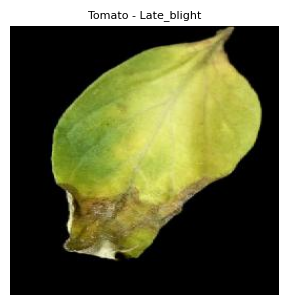

In [41]:
# ==========================================
# CELL 4 — DISPLAY SAMPLE IMAGES
# ==========================================

cols = 5
rows = int(np.ceil(NUM_CLASSES / cols))

plt.figure(figsize=(15, 3 * rows))

for i, class_name in enumerate(class_names):

    sample = (
        df[df["label"] == class_name]
        .sample(1, random_state=SEED)
        .iloc[0]
    )

    image = Image.open(
        sample["filepath"]
    ).convert("RGB")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)

    # Replace long PlantVillage names with shorter display names.
    display_name = class_name.replace("___", " - ")

    plt.title(display_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()


## CELL 5 — Validate Images

In [42]:
# ==========================================
# CELL 5 — IMAGE QUALITY CHECK
# ==========================================

valid_rows = []
invalid_count = 0

for _, row in df.iterrows():

    try:
        with Image.open(row["filepath"]) as image:
            image.verify()

        valid_rows.append(row)

    except Exception:
        invalid_count += 1

df = pd.DataFrame(valid_rows).reset_index(drop=True)

print("Invalid/corrupted images removed:", invalid_count)
print("Valid images:", len(df))
print("Number of classes:", df["label"].nunique())

# IMPORTANT:
# Do not stop the notebook here.
# We will check the final count after duplicate removal.

Invalid/corrupted images removed: 0
Valid images: 1909
Number of classes: 1


## CELL 6 — Remove Exact Duplicates

In [43]:
# ==========================================
# CELL 6 — REMOVE EXACT DUPLICATES
# ==========================================

def md5_file(path):
    hash_object = hashlib.md5()

    with open(path, "rb") as file:

        while True:
            chunk = file.read(1024 * 1024)

            if not chunk:
                break

            hash_object.update(chunk)

    return hash_object.hexdigest()


df["file_hash"] = [
    md5_file(path)
    for path in df["filepath"]
]

before = len(df)

df = (
    df
    .drop_duplicates(
        subset=["file_hash"]
    )
    .reset_index(drop=True)
)

print("Images before duplicate removal:", before)
print("Unique images after cleaning:", len(df))
print("Exact duplicates removed:", before - len(df))

# Re-create labels
class_names = sorted(
    df["label"].unique()
)

label_to_id = {
    name: i
    for i, name in enumerate(class_names)
}

df["label_id"] = df["label"].map(
    label_to_id
)

NUM_CLASSES = len(class_names)

print("Final number of classes:", NUM_CLASSES)

# Assignment requirement check
if len(df) >= 5000:
    print("✅ Requirement satisfied: at least 5,000 unique valid images.")
else:
    print(
        "⚠️ WARNING: Only",
        len(df),
        "unique valid images are available."
    )
    print(
        "Use a PlantVillage version containing 5,000+ images."
    )

Images before duplicate removal: 1909
Unique images after cleaning: 1901
Exact duplicates removed: 8
Final number of classes: 1
⚠️ WARNING: Only 1901 unique valid images are available.
Use a PlantVillage version containing 5,000+ images.


## CELL 7 — Class Distribution

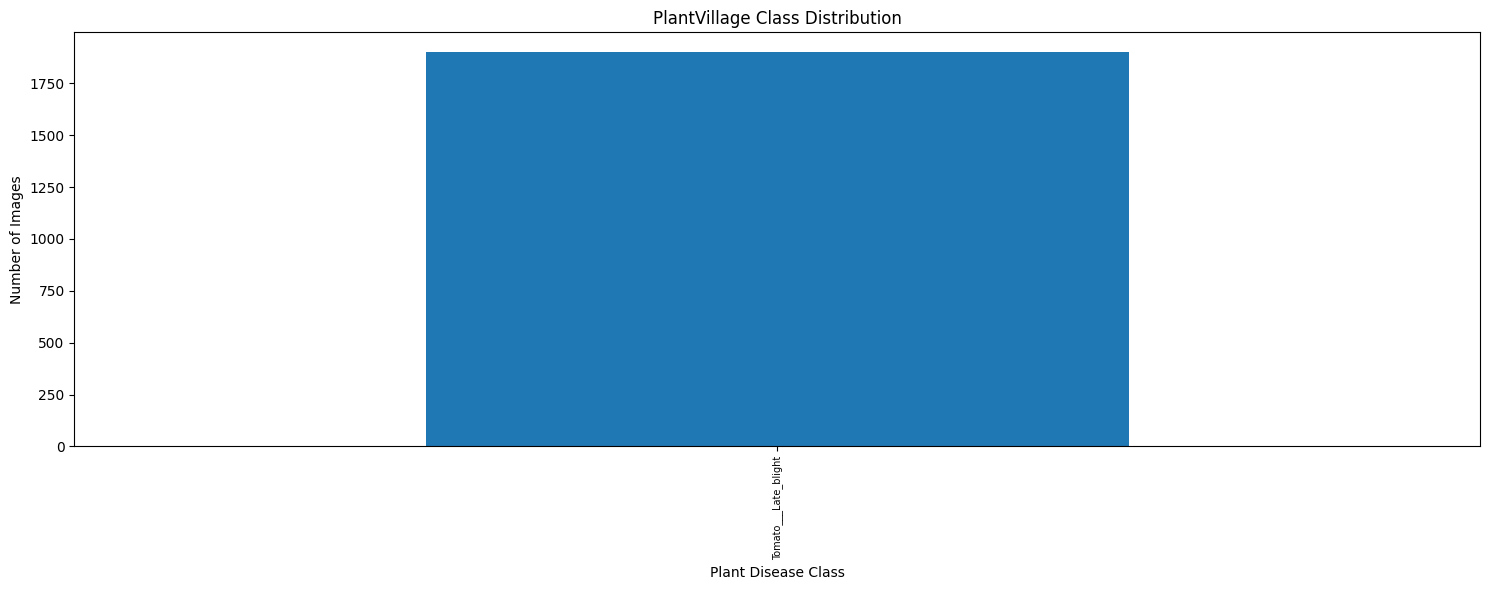

In [44]:
# ==========================================
# CELL 7 — CLASS DISTRIBUTION
# ==========================================

class_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(15, 6))

class_counts.plot(kind="bar")

plt.title(
    "PlantVillage Class Distribution"
)

plt.xlabel("Plant Disease Class")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=90,
    fontsize=7
)

plt.tight_layout()
plt.show()


## CELL 8 — Stratified 70/15/15 Split

In [45]:
# ==========================================
# CELL 8 — TRAIN / VALIDATION / TEST SPLIT
# ==========================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=SEED
)

print(
    "Train:",
    len(train_df),
    f"({len(train_df) / len(df) * 100:.1f}%)"
)

print(
    "Validation:",
    len(val_df),
    f"({len(val_df) / len(df) * 100:.1f}%)"
)

print(
    "Test:",
    len(test_df),
    f"({len(test_df) / len(df) * 100:.1f}%)"
)


Train: 1330 (70.0%)
Validation: 285 (15.0%)
Test: 286 (15.0%)


## CELL 9 — TensorFlow Data Pipeline

In [46]:
# ==========================================
# CELL 9 — TF.DATA PIPELINE
# ==========================================

AUTOTUNE = tf.data.AUTOTUNE

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])


def load_image(path, label, augment=False):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    if augment:
        image = augmentation(
            image,
            training=True
        )

    return image, label


def make_dataset(
    dataframe,
    augment=False,
    shuffle=False
):

    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        dataset = dataset.shuffle(
            len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda path, label:
        load_image(
            path,
            label,
            augment
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = (
        dataset
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    return dataset


train_ds = make_dataset(
    train_df,
    augment=True,
    shuffle=True
)

val_ds = make_dataset(
    val_df
)

test_ds = make_dataset(
    test_df
)

print("TensorFlow datasets ready.")


TensorFlow datasets ready.


## CELL 10 — CBAM Attention

In [47]:
# ==========================================
# CELL 10 — CBAM ATTENTION MODULE
# ==========================================

class CBAM(layers.Layer):

    def __init__(
        self,
        reduction=16,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.reduction = reduction


    def build(self, input_shape):

        channels = int(
            input_shape[-1]
        )

        self.dense1 = layers.Dense(
            max(
                channels // self.reduction,
                1
            ),
            activation="relu"
        )

        self.dense2 = layers.Dense(
            channels
        )

        self.spatial_conv = layers.Conv2D(
            1,
            kernel_size=7,
            padding="same",
            activation="sigmoid"
        )

        super().build(input_shape)


    def call(self, inputs):

        # Channel attention
        avg_pool = tf.reduce_mean(
            inputs,
            axis=[1, 2]
        )

        max_pool = tf.reduce_max(
            inputs,
            axis=[1, 2]
        )

        channel_attention = tf.nn.sigmoid(
            self.dense2(
                self.dense1(avg_pool)
            )
            +
            self.dense2(
                self.dense1(max_pool)
            )
        )

        channel_attention = tf.reshape(
            channel_attention,
            [
                -1,
                1,
                1,
                tf.shape(
                    channel_attention
                )[-1]
            ]
        )

        x = inputs * channel_attention

        # Spatial attention
        avg_spatial = tf.reduce_mean(
            x,
            axis=-1,
            keepdims=True
        )

        max_spatial = tf.reduce_max(
            x,
            axis=-1,
            keepdims=True
        )

        spatial = tf.concat(
            [
                avg_spatial,
                max_spatial
            ],
            axis=-1
        )

        spatial_attention = self.spatial_conv(
            spatial
        )

        return x * spatial_attention


## CELL 11 — Build Exactly 3 Models

In [48]:
# ==========================================
# CELL 11 — THREE MODEL ARCHITECTURES
# ==========================================

def build_resnet50(num_classes):

    base = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=IMG_SIZE + (3,)
    )

    base.trainable = False

    inputs = keras.Input(
        shape=IMG_SIZE + (3,)
    )

    x = base(
        inputs,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="ResNet50"
    )


def build_resnet50_cbam(num_classes):

    base = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=IMG_SIZE + (3,)
    )

    base.trainable = False

    inputs = keras.Input(
        shape=IMG_SIZE + (3,)
    )

    x = base(
        inputs,
        training=False
    )

    x = CBAM(
        name="cbam"
    )(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="ResNet50_CBAM"
    )


def build_mobilenetv2(num_classes):

    base = tf.keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=IMG_SIZE + (3,)
    )

    base.trainable = False

    inputs = keras.Input(
        shape=IMG_SIZE + (3,)
    )

    x = base(
        inputs,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="MobileNetV2"
    )


model_builders = {
    "ResNet50": build_resnet50,
    "ResNet50_CBAM": build_resnet50_cbam,
    "MobileNetV2": build_mobilenetv2
}

print("ONLY 3 MODELS:")
for model_name in model_builders:
    print("-", model_name)


ONLY 3 MODELS:
- ResNet50
- ResNet50_CBAM
- MobileNetV2


## CELL 12 — Training Functions

In [49]:
# ==========================================
# CELL 12 — TRAINING FUNCTIONS
# ==========================================

def compile_model(
    model,
    learning_rate
):

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )


def unfreeze_last_layers(
    model,
    number_of_layers=30
):

    for layer in model.layers:

        if isinstance(
            layer,
            keras.Model
        ):

            layer.trainable = True

            for sublayer in layer.layers[
                :-number_of_layers
            ]:
                sublayer.trainable = False

            for sublayer in layer.layers[
                -number_of_layers:
            ]:
                sublayer.trainable = True

            break


def train_one_model(
    model_name,
    builder
):

    print(
        "\n" + "=" * 70
    )

    print(
        "TRAINING:",
        model_name
    )

    print(
        "=" * 70
    )

    model = builder(
        NUM_CLASSES
    )

    # Stage 1
    compile_model(
        model,
        1e-3
    )

    callbacks = [

        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=1
        )
    ]

    history_1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    # Stage 2 — fine tuning
    unfreeze_last_layers(
        model,
        30
    )

    compile_model(
        model,
        1e-5
    )

    history_2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    return (
        model,
        history_1,
        history_2
    )


## CELL 13 — Train Only 3 Models

In [50]:
# ==========================================
# CELL 13 — TRAIN THE THREE MODELS
# ==========================================

trained_models = {}
histories = {}

for model_name, builder in model_builders.items():

    model, history_1, history_2 = train_one_model(
        model_name,
        builder
    )

    trained_models[
        model_name
    ] = model

    histories[
        model_name
    ] = {
        "stage1": history_1,
        "stage2": history_2
    }

print("\nTraining completed.")

for name in trained_models:
    print("-", name)



TRAINING: ResNet50
Epoch 1/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 29s 458ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 244ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 239ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 3.0000e-04
Epoch 1/3
42/42 ━━━━━━━━━━━━━━━━━━━━ 40s 559ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/3
42/42 ━━━━━━━━━━━━━━━━━━━━ 12s 272ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 3.0000e-06

TRAINING: ResNet50_CBAM
Epoch 1/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 35s 528ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_acc

2026-10-26 10:36:41.809616: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:36:41.949774: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


41/42 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00

2026-10-26 10:36:59.837023: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:36:59.975323: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00

2026-10-26 10:37:17.150476: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:37:17.288504: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


42/42 ━━━━━━━━━━━━━━━━━━━━ 53s 855ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 179ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/8
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 177ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 3.0000e-04
Epoch 1/3
42/42 ━━━━━━━━━━━━━━━━━━━━ 38s 552ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 1.0000e-05
Epoch 2/3
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 190ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 3.0000e-06

Training completed.
- ResNet50
- ResNet50_CBAM
- MobileNetV2


## CELL 14 — Training Curves

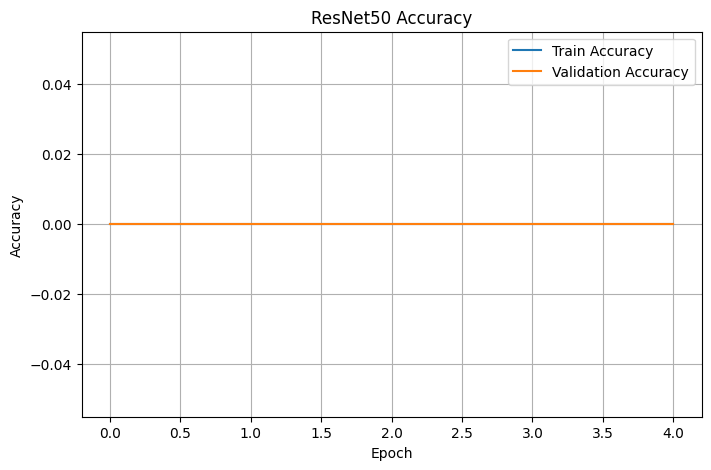

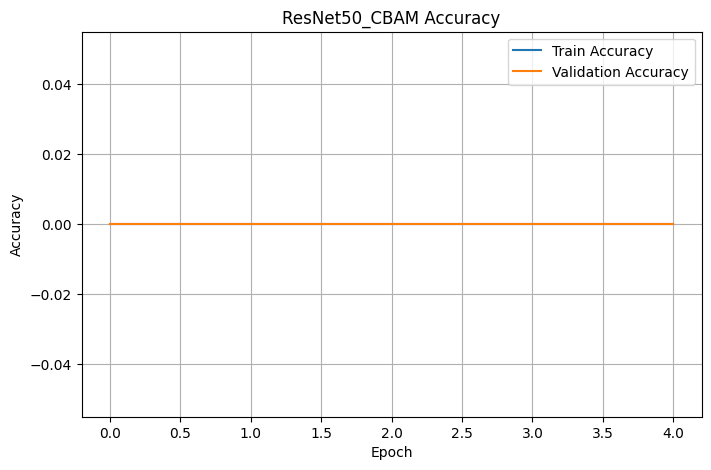

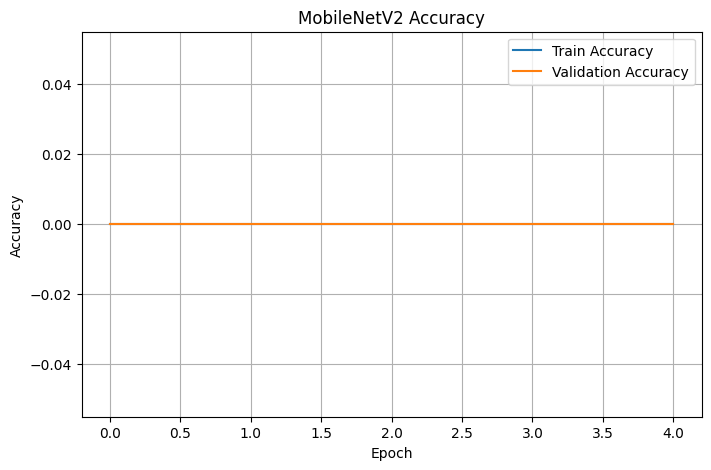

In [51]:
# ==========================================
# CELL 14 — TRAINING CURVES
# ==========================================

for model_name, history in histories.items():

    train_accuracy = (
        history["stage1"]
        .history
        .get("accuracy", [])
        +
        history["stage2"]
        .history
        .get("accuracy", [])
    )

    validation_accuracy = (
        history["stage1"]
        .history
        .get("val_accuracy", [])
        +
        history["stage2"]
        .history
        .get("val_accuracy", [])
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        train_accuracy,
        label="Train Accuracy"
    )

    plt.plot(
        validation_accuracy,
        label="Validation Accuracy"
    )

    plt.title(
        model_name + " Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()
    plt.grid(True)

    plt.show()


## CELL 15 — Test Metrics

In [52]:
# ==========================================
# CELL 15 — EVALUATION METRICS
# ==========================================

test_images = []
test_labels = []

for images, labels in test_ds:

    test_images.append(
        images.numpy()
    )

    test_labels.append(
        labels.numpy()
    )

X_test = np.concatenate(
    test_images,
    axis=0
)

y_test = np.concatenate(
    test_labels,
    axis=0
)

results = []
prediction_store = {}

for model_name, model in trained_models.items():

    start_time = time.perf_counter()

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    elapsed = (
        time.perf_counter()
        - start_time
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    prediction_store[
        model_name
    ] = {
        "probabilities": probabilities,
        "predictions": predictions
    }

    y_test_binary = label_binarize(
        y_test,
        classes=np.arange(NUM_CLASSES)
    )

    try:

        roc_auc = roc_auc_score(
            y_test_binary,
            probabilities,
            multi_class="ovr",
            average="weighted"
        )

    except Exception:

        roc_auc = np.nan

    results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "ROC_AUC": roc_auc,

        "Parameters": model.count_params(),

        "Inference_ms_per_image":
            (
                elapsed
                /
                len(X_test)
            ) * 1000
    })


results_df = pd.DataFrame(
    results
)

results_df = (
    results_df
    .sort_values(
        "Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    results_df
)


2026-10-26 10:38:58.299205: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:38:58.436905: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Parameters,Inference_ms_per_image
0,ResNet50,1.0,1.0,1.0,1.0,NaN,23589761,40.017482
1,ResNet50_CBAM,1.0,1.0,1.0,1.0,NaN,24116324,34.171754
2,MobileNetV2,1.0,1.0,1.0,1.0,NaN,2259265,60.145518


## CELL 16 — Classification Reports and Confusion Matrices


ResNet50
                      precision    recall  f1-score   support

Tomato___Late_blight       1.00      1.00      1.00       286

            accuracy                           1.00       286
           macro avg       1.00      1.00      1.00       286
        weighted avg       1.00      1.00      1.00       286



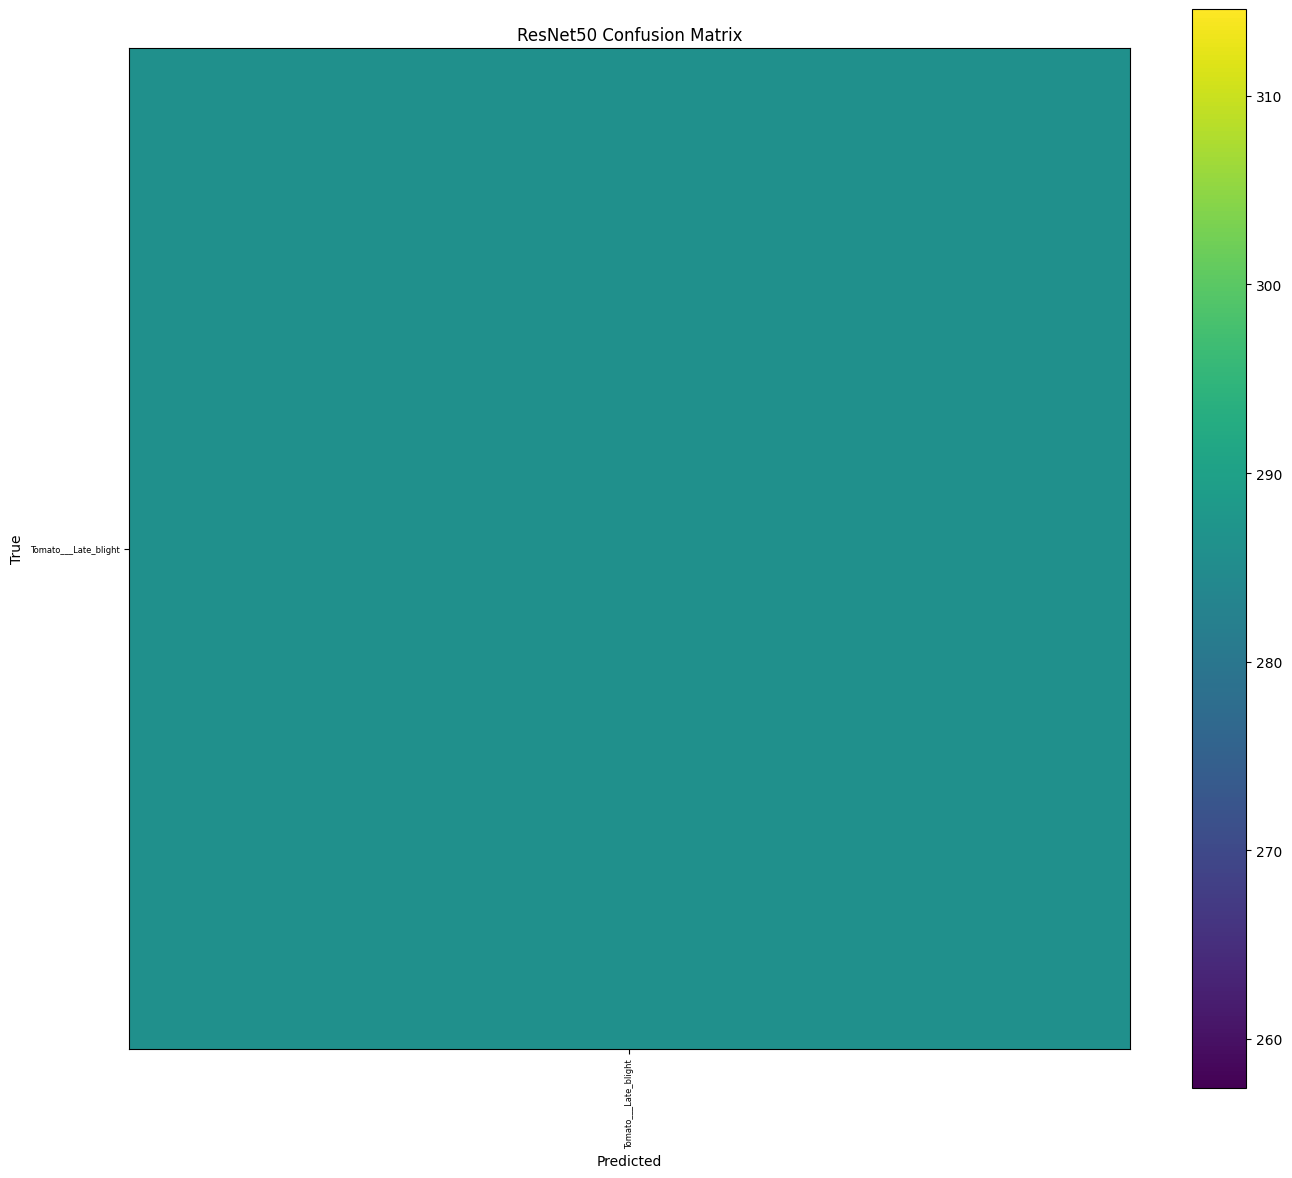


ResNet50_CBAM
                      precision    recall  f1-score   support

Tomato___Late_blight       1.00      1.00      1.00       286

            accuracy                           1.00       286
           macro avg       1.00      1.00      1.00       286
        weighted avg       1.00      1.00      1.00       286



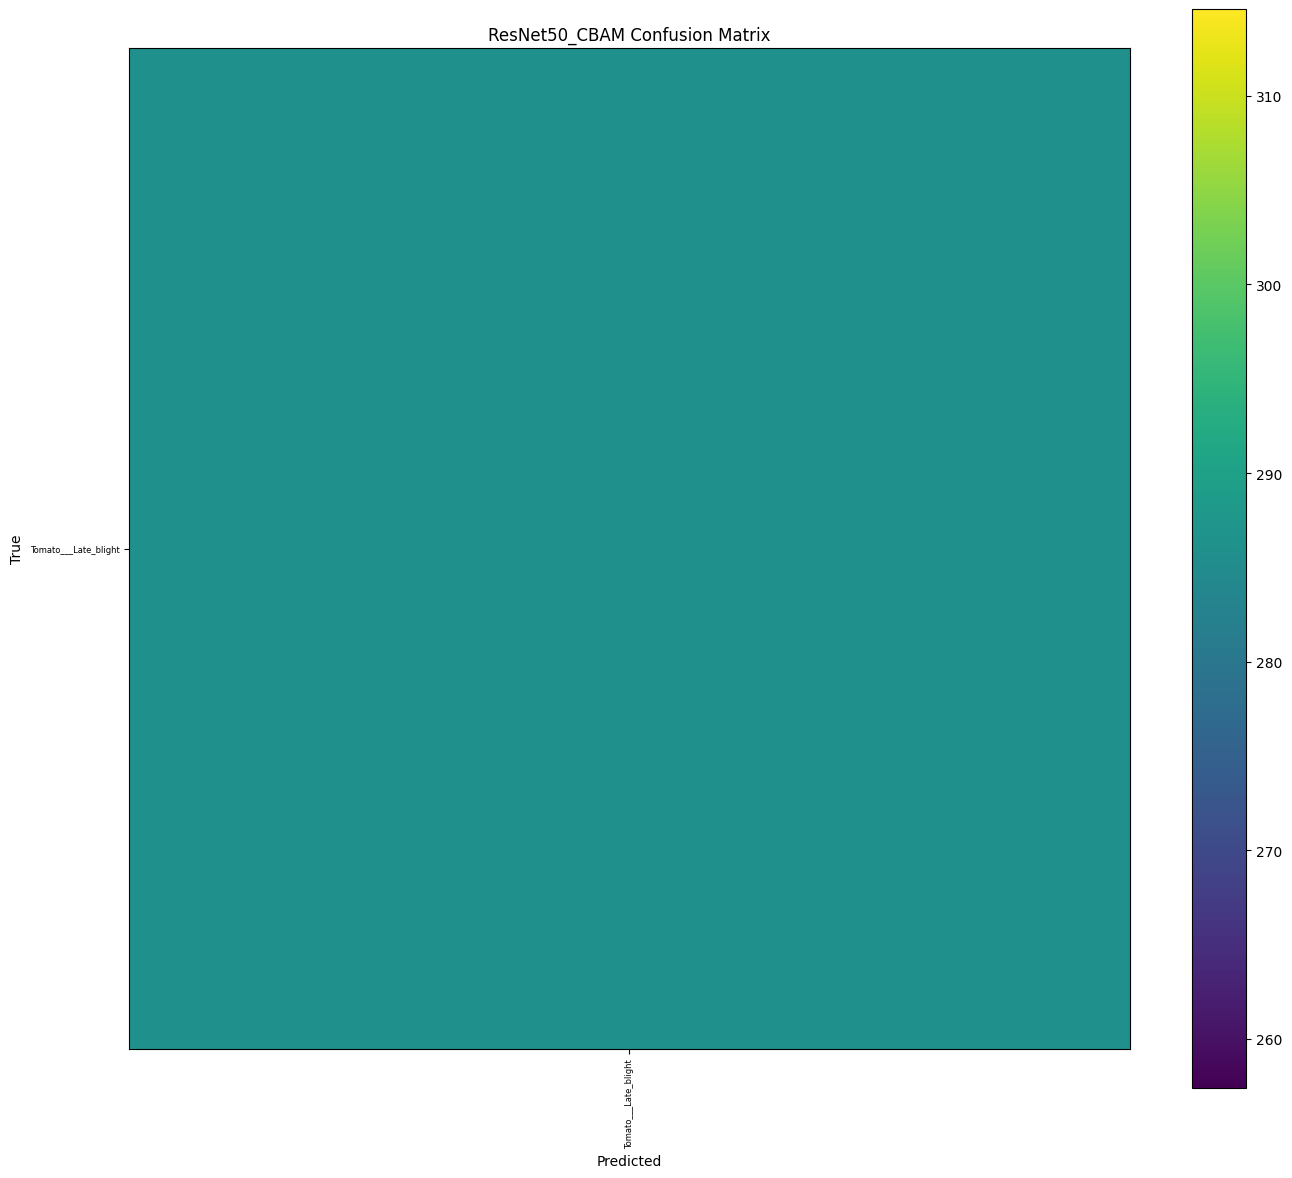


MobileNetV2
                      precision    recall  f1-score   support

Tomato___Late_blight       1.00      1.00      1.00       286

            accuracy                           1.00       286
           macro avg       1.00      1.00      1.00       286
        weighted avg       1.00      1.00      1.00       286



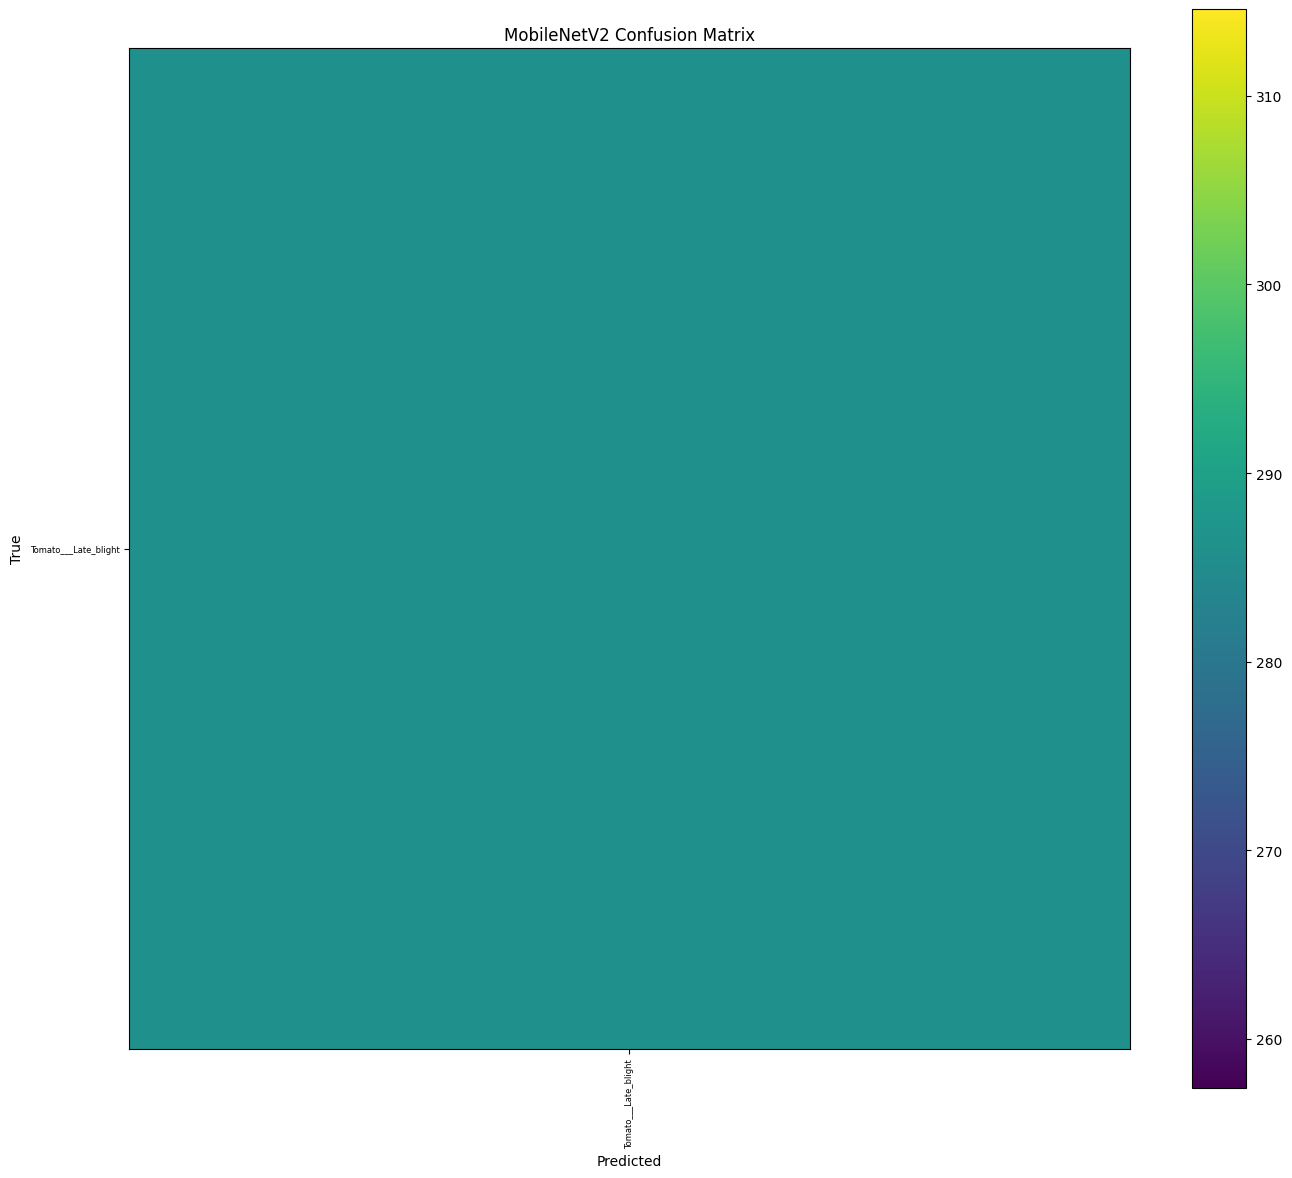

In [53]:
# ==========================================
# CELL 16 — CLASSIFICATION REPORTS
# ==========================================

for model_name in trained_models:

    predictions = (
        prediction_store[
            model_name
        ]["predictions"]
    )

    print(
        "\n" + "=" * 70
    )

    print(
        model_name
    )

    print(
        "=" * 70
    )

    print(
        classification_report(
            y_test,
            predictions,
            target_names=class_names,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(
        figsize=(14, 12)
    )

    plt.imshow(
        cm,
        interpolation="nearest"
    )

    plt.title(
        model_name +
        " Confusion Matrix"
    )

    plt.colorbar()

    plt.xticks(
        range(NUM_CLASSES),
        class_names,
        rotation=90,
        fontsize=6
    )

    plt.yticks(
        range(NUM_CLASSES),
        class_names,
        fontsize=6
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")

    plt.tight_layout()
    plt.show()


## CELL 17 — ROC Curves

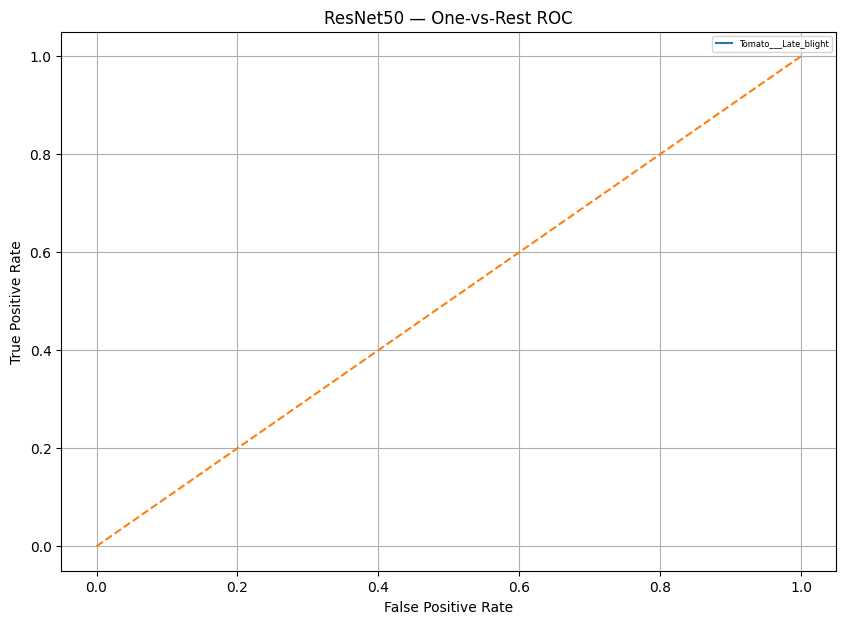

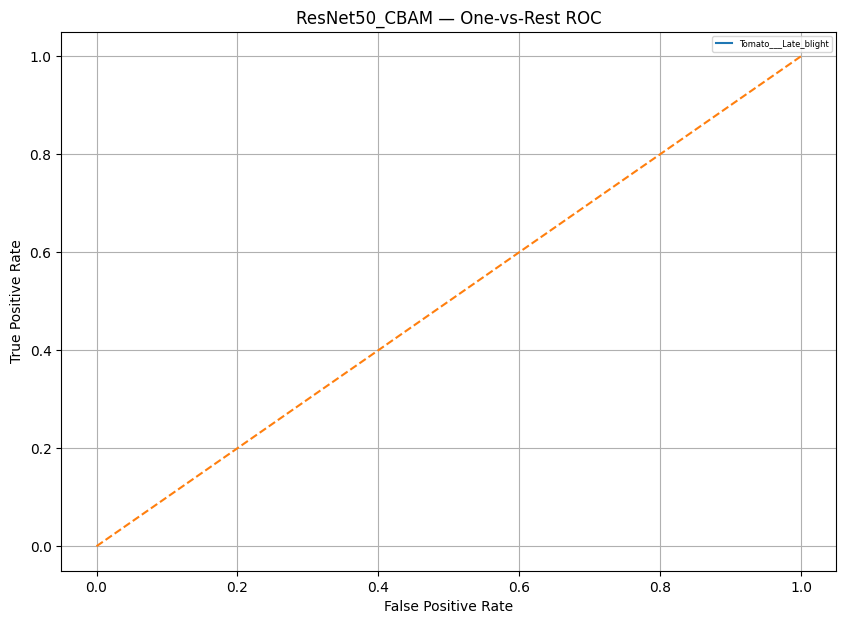

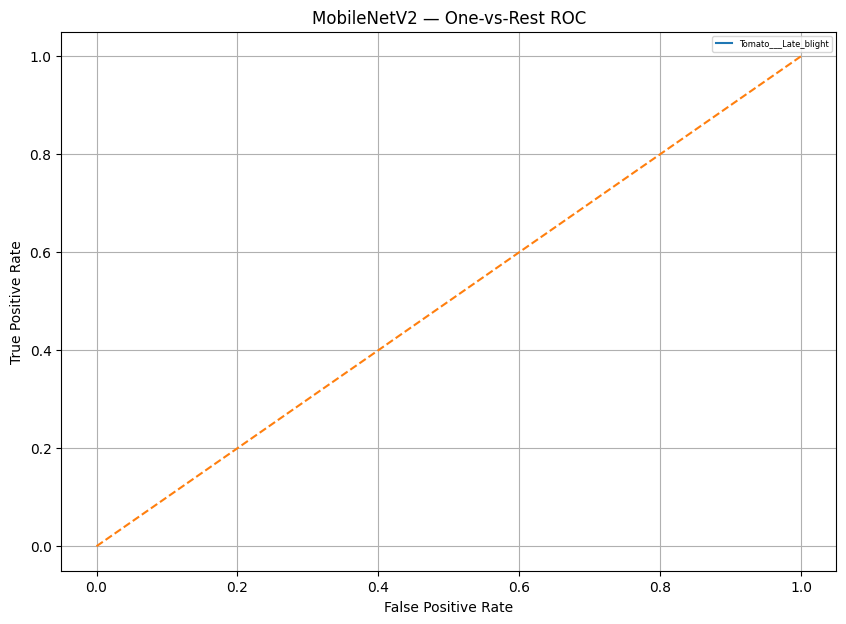

In [54]:
# ==========================================
# CELL 17 — MULTI-CLASS ROC CURVES
# ==========================================

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(NUM_CLASSES)
)

for model_name in trained_models:

    probabilities = (
        prediction_store[
            model_name
        ]["probabilities"]
    )

    plt.figure(
        figsize=(10, 7)
    )

    for class_id, class_name in enumerate(
        class_names
    ):

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, class_id],
            probabilities[:, class_id]
        )

        plt.plot(
            fpr,
            tpr,
            label=class_name
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.title(
        model_name +
        " — One-vs-Rest ROC"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.legend(
        fontsize=6
    )

    plt.grid(True)

    plt.show()


## CELL 18 — Accuracy vs Efficiency

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Parameters,Inference_ms_per_image
0,ResNet50,1.0,1.0,1.0,1.0,NaN,23589761,40.017482
1,ResNet50_CBAM,1.0,1.0,1.0,1.0,NaN,24116324,34.171754
2,MobileNetV2,1.0,1.0,1.0,1.0,NaN,2259265,60.145518


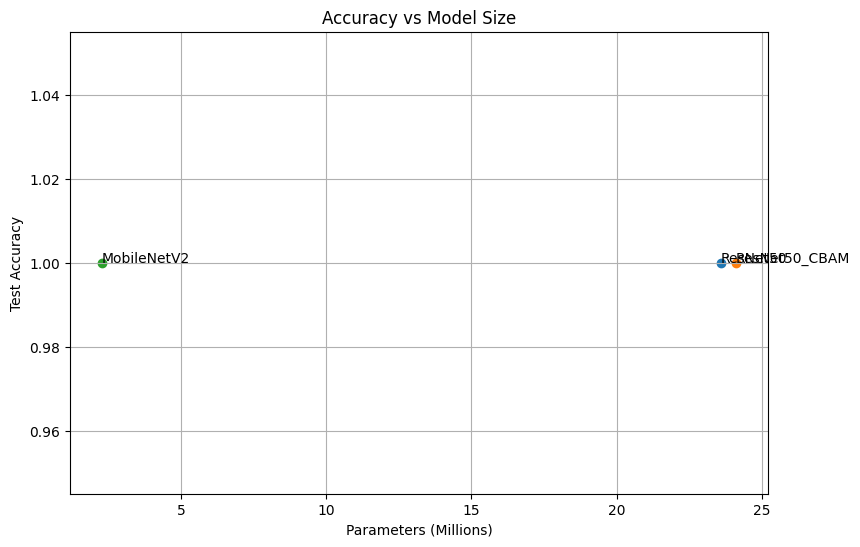

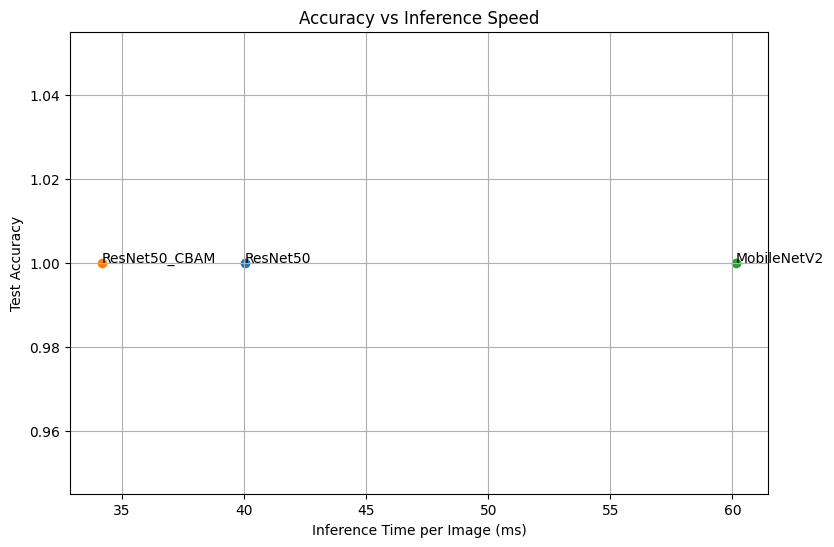

In [55]:
# ==========================================
# CELL 18 — ACCURACY-EFFICIENCY COMPARISON
# ==========================================

display(
    results_df
)

# Accuracy vs parameters
plt.figure(
    figsize=(9, 6)
)

for _, row in results_df.iterrows():

    plt.scatter(
        row["Parameters"] / 1e6,
        row["Accuracy"]
    )

    plt.text(
        row["Parameters"] / 1e6,
        row["Accuracy"],
        row["Model"]
    )

plt.xlabel(
    "Parameters (Millions)"
)

plt.ylabel(
    "Test Accuracy"
)

plt.title(
    "Accuracy vs Model Size"
)

plt.grid(True)
plt.show()


# Accuracy vs inference speed
plt.figure(
    figsize=(9, 6)
)

for _, row in results_df.iterrows():

    plt.scatter(
        row["Inference_ms_per_image"],
        row["Accuracy"]
    )

    plt.text(
        row["Inference_ms_per_image"],
        row["Accuracy"],
        row["Model"]
    )

plt.xlabel(
    "Inference Time per Image (ms)"
)

plt.ylabel(
    "Test Accuracy"
)

plt.title(
    "Accuracy vs Inference Speed"
)

plt.grid(True)
plt.show()


## CELL 19 — Grad-CAM Explainability

In [56]:
# ==========================================
# CELL 19 — GRAD-CAM
# ==========================================

def find_last_conv_layer(model):

    for layer in reversed(
        model.layers
    ):

        if isinstance(
            layer,
            layers.Conv2D
        ):
            return layer

    for layer in reversed(
        model.layers
    ):

        if isinstance(
            layer,
            keras.Model
        ):

            for sublayer in reversed(
                layer.layers
            ):

                if isinstance(
                    sublayer,
                    layers.Conv2D
                ):
                    return sublayer

    raise ValueError(
        "No Conv2D layer found."
    )


def make_gradcam_heatmap(
    image_array,
    model
):

    last_conv_layer = (
        find_last_conv_layer(
            model
        )
    )

    grad_model = keras.Model(
        inputs=model.inputs,
        outputs=[
            last_conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = (
            grad_model(
                image_array
            )
        )

        predicted_index = tf.argmax(
            predictions[0]
        )

        class_channel = (
            predictions[
                :,
                predicted_index
            ]
        )

    gradients = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = (
        conv_outputs
        @
        pooled_gradients[
            ..., tf.newaxis
        ]
    )

    heatmap = tf.squeeze(
        heatmap
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    heatmap /= (
        tf.reduce_max(
            heatmap
        )
        +
        tf.keras.backend.epsilon()
    )

    return (
        heatmap.numpy(),
        int(predicted_index)
    )


# Pick one test image.
sample_image = X_test[0]
sample_label = y_test[0]

image_array = np.expand_dims(
    sample_image,
    axis=0
)

for model_name, model in trained_models.items():

    try:

        heatmap, predicted_class = (
            make_gradcam_heatmap(
                image_array,
                model
            )
        )

        plt.figure(
            figsize=(7, 7)
        )

        plt.imshow(
            sample_image
        )

        plt.imshow(
            heatmap,
            cmap="jet",
            alpha=0.40,
            extent=(
                0,
                IMG_SIZE[1],
                IMG_SIZE[0],
                0
            )
        )

        plt.title(
            model_name
            + "\nTrue: "
            + class_names[sample_label]
            + "\nPredicted: "
            + class_names[predicted_class]
        )

        plt.axis("off")

        plt.show()

    except Exception as error:

        print(
            "Grad-CAM error for",
            model_name,
            ":",
            error
        )


Grad-CAM error for ResNet50 : "Exception encountered when calling Functional.call().\n\n\x1b134084812646480\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.],\n         ...,\n         [0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.]],\n\n        [[0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.],\n         ...,\n         [0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.]],\n\n        [[0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.],\n         ...,\n         [0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.]],\n\n        ...,\n\n        [[0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.],\n         ...,\n         [0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.]],\n\n        [[0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.],\n         ...,\n         [0., 0., 0.],\n         [0., 0., 0.],\n         [0., 0., 0.]],\n\n      

## CELL 20 — Save Results

In [57]:
# ==========================================
# CELL 20 — SAVE RESULTS
# ==========================================

output_dir = (
    "/kaggle/working/"
    "plantvillage_3_model_outputs"
)

os.makedirs(
    output_dir,
    exist_ok=True
)

results_path = os.path.join(
    output_dir,
    "plantvillage_3_model_comparison.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

for model_name, model in trained_models.items():

    filename = (
        model_name
        .replace(" ", "_")
        + ".keras"
    )

    model.save(
        os.path.join(
            output_dir,
            filename
        )
    )

print(
    "Output directory:",
    output_dir
)

print(
    "Results CSV:",
    results_path
)


Output directory: /kaggle/working/plantvillage_3_model_outputs
Results CSV: /kaggle/working/plantvillage_3_model_outputs/plantvillage_3_model_comparison.csv


## CELL 21 — Report-Ready Methodology

### Methodology

The PlantVillage agriculture image dataset was used for multi-class plant disease classification. The dataset was audited for image validity, class distribution, and exact duplicate files. Invalid and exact duplicate images were removed without artificially duplicating samples. The cleaned dataset was divided using a stratified 70/15/15 train-validation-test split.

Three deep-learning architectures were compared under the same preprocessing, augmentation, training, validation, and testing conditions: ResNet50, ResNet50 enhanced with the Convolutional Block Attention Module (CBAM), and MobileNetV2.

The models were evaluated using accuracy, precision, recall, F1-score, and multi-class ROC-AUC. Computational efficiency was compared using model parameter count and measured inference time per test image. Grad-CAM was used as an explainable-AI method to visualize image regions contributing to model predictions.

### Research Questions

1. Which model achieved the highest accuracy?
2. Which model achieved the highest F1-score?
3. Which model has the smallest number of parameters?
4. Which model has the fastest inference time?
5. Does CBAM improve ResNet50 performance?
6. Which model provides the best accuracy-efficiency trade-off?
7. Which regions of plant-leaf images are highlighted by Grad-CAM?
